In [1]:
import pandas as pd
from datetime import datetime
import os
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./CAE/New/'))
file_path = cPath + 'Hourly5837.xlsx'
myData = pd.read_csv('myData.labels.csv', parse_dates=['Start'], date_format='%Y-%m-%d %H:%M:%S')
myData.set_index('Start', drop = False, inplace=True)
#myData.set_index('Start', drop = False, inplace=True)
print(myData.head)
print(myData.index.name)
#myData['Delta'] = 0
# Adding a 'label' column to differentiate between OffPeak, OnPeak, and OnPeakHigh 
#myData['label'] = 'OffPeak'
#myData.head
#print(myData['Start'])

<bound method NDFrame.head of                                   Start              Start.1  Usage     Delta  \
Start                                                                           
2023-10-01 01:00:00 2023-10-01 01:00:00  2023-10-01 01:00:00   1039 -0.006389   
2023-10-01 02:00:00 2023-10-01 02:00:00  2023-10-01 02:00:00   1016 -0.017500   
2023-10-01 03:00:00 2023-10-01 03:00:00  2023-10-01 03:00:00    953 -0.041389   
2023-10-01 04:00:00 2023-10-01 04:00:00  2023-10-01 04:00:00    804  0.014444   
2023-10-01 05:00:00 2023-10-01 05:00:00  2023-10-01 05:00:00    856 -0.005000   
...                                 ...                  ...    ...       ...   
2024-09-30 20:00:00 2024-09-30 20:00:00  2024-09-30 20:00:00    866 -0.021667   
2024-09-30 21:00:00 2024-09-30 21:00:00  2024-09-30 21:00:00    788  0.125556   
2024-09-30 22:00:00 2024-09-30 22:00:00  2024-09-30 22:00:00   1240 -0.008056   
2024-09-30 23:00:00 2024-09-30 23:00:00  2024-09-30 23:00:00   1211 -0.023611  

In [3]:
# Plot with area fill and color by label
fig = px.area(
    myData, 
    x='Start', 
    y='Usage', 
    color='label', 
    hover_data=['Usage'],
    title='Day vs Night Filled Area'
    )
# fig = px.scatter(
#     Y4,
#     x='Start',
#     y='USAGE',
#     color='label',
#     title='Electricity Usage Over Time',
#     labels={'USAGE': 'Electricity Usage (kWh)', 'Time': 'Timestamp'},
#     # color_discrete_map={
#     #     'Low': 'green',
#     #     'Medium': 'orange',
#     #     'High': 'red'
#     # }
# )
# fig.update_traces(mode='lines+markers')
fig.show()

# fig = px.line(
#     Y4,
#     x='Start',
#     y='USAGE',
#     title='Interactive Plot of Start Times',
#     labels={'Parsed Start Time': 'Start Time', 'Value': 'Some Metric'},
#     color='label',
#     hover_data=Y4.columns
# )
# fig.show()


/usr/lib/python3/dist-packages/_plotly_utils/basevalidators.py:105: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  v = v.dt.to_pydatetime()


In [5]:
# Example assumes 'myTest' already exists and has datetime index
# Reset index to make datetime a column (Plotly Express needs it)
#df = Y4.reset_index().rename(columns={'index': 'Time'})
df = myData 

# Create figure
fig = go.Figure()

# Define label colors
label_colors = {
    'OffPeak': 'green',
    'sOnPeak': 'orange',
    'sOnPeakHigh': 'red',
    'wOnPeak' : 'purple',
    'wOnPeakHigh': 'blue'
}

# Plot each label group separately
for lab in df['label'].unique():
    group = df[df['label'] == lab]
    fig.add_trace(go.Scatter(
        x=group['Start'],
        y=group['Usage'],
        mode='lines+markers',
        name=lab,
        line=dict(color=label_colors.get(lab, 'gray')),
        marker=dict(size=5),
        connectgaps=False  # <-- This avoids connecting across gaps
    ))

# Update layout
fig.update_layout(
    title='Electricity Usage Over Time by Label',
    xaxis_title='Time',
    yaxis_title='Electricity Usage (kWh)',
    legend_title='Usage Label',
    hovermode='x unified'
)

# Show the figure
fig.show()

/usr/lib/python3/dist-packages/_plotly_utils/basevalidators.py:105: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



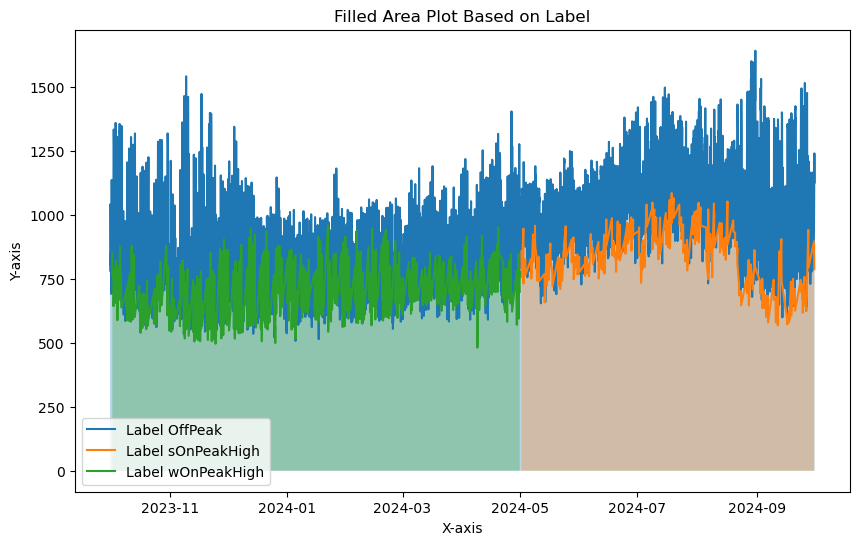

In [6]:
plt.figure(figsize=(10, 6))

# Fill the area under the curve based on the label column
for label, group in myData.groupby('label'):
    plt.plot(group['Start'], group['Usage'], label=f'Label {label}')
    plt.fill_between(group['Start'], group['Usage'], alpha=0.3)

plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Filled Area Plot Based on Label')
plt.legend()
plt.show()


In [8]:

# Create a figure
fig = go.Figure()

# Fill the area under the curve based on the label column
for label, group in myData.groupby('label'):
	fig.add_trace(go.Scatter(
		x=group.index,
		y=group['Usage'], 
		mode='lines', 
		name=f'Label {label}',
		fill='tozeroy',
#		showlegend=True,
		connectgaps=False  # Prevent connecting lines between segments
	))

# Update layout
fig.update_layout(
	title='Filled Area Plot Based on Label',
	xaxis_title='Date-Time',
	yaxis_title='Electricity Usage (Wh)'
)

# Show the plot
fig.show()

In [10]:
tdata = myData 
mask = (myData['label'] != 'sOnPeakHigh') or (myData['label'] != 'sOnPeak') 
tdata.loc[mask, 'Usage'] = ''
print(tdata)

# Create a figure
fig = go.Figure()

# Fill the area under the curve based on the label column
fig.add_trace(go.Scatter(
	x=tdata.index,
	y=tdata['Usage'], 
	mode = 'lines',
	name=f'Label {label}',
	fill='tozeroy',
#		showlegend=True,
	connectgaps=False# Prevent connecting lines between segments
))

# Update layout
fig.update_layout(
	title='Filled Area Plot Based on Label',
	xaxis_title='Date-Time',
	yaxis_title='Electricity Usage (Wh)'
)

# Show the plot
fig.show()

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().